<div>
    <span style ="font-size: 32px; font-weight: bold; color: #8EB944">
        Imports
    </span>
    
<hr style="color: #8EB944; height: 3px;background-color: #8EB944;border: none">
</div>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
import numpy as np
from itertools import product


In [2]:
from prophet import Prophet
from prophet.diagnostics import cross_validation, performance_metrics
from prophet.plot import plot_cross_validation_metric

In [3]:
from helper_functions import find_gaps, plot_forecast, plot_subseries, is_in_gap

In [4]:
holidays_str = [
    '2018-01-01','2018-01-15', '2018-02-19','2018-03-31','2018-05-28','2018-07-04',
    '2018-09-03','2018-10-08','2018-11-12','2018-11-22','2018-11-23','2018-12-25',
    '2019-01-01','2019-01-21', '2019-02-18','2019-04-01','2019-05-27','2019-07-04',
    '2019-09-02','2019-11-11','2019-11-28','2019-11-29','2019-12-25',
    '2020-01-01','2020-01-20', '2020-02-17','2020-03-31','2020-05-25','2020-07-04',
    '2020-09-07','2020-11-11','2020-11-26','2020-11-27','2020-12-25',
    '2021-01-01','2021-01-18', '2021-02-15','2021-03-31','2021-05-31','2021-07-05',
    '2021-09-06','2021-11-11','2021-11-25','2021-11-26','2021-12-25',
    '2022-01-01','2022-01-17', '2022-02-21','2022-03-31','2022-05-30','2022-07-04',
    '2022-09-05','2022-11-11','2022-11-24','2022-11-25', '2022-12-26'
]



holidays = pd.DataFrame({
      'holiday': ['Holiday'] * len(holidays_str),  
    'ds': pd.to_datetime(holidays_str),
  'lower_window': 0,
  'upper_window': 0,
})




<div>
    <span style ="font-size: 32px; font-weight: bold; color: #8EB944">
        Hyperparameter Search
    </span>
    
<hr style="color: #8EB944; height: 3px;background-color: #8EB944;border: none">
</div>

<h2>Parameters for grid search</h2>


<ul>
    <li><strong>Seasonality Prior Scale: </strong> 50
    <li><strong>Changepoint Range: </strong> 0.95
    <li><strong>Changepoint Prior Scale:</strong> 0.1
    <li><strong>Holidays Prior Scale:</strong> 1


In [33]:
# === Step 1: Prepare data ===
data = pd.read_csv('utilization_final.csv')
#data = data[data.site_01==0]

# make the binary features numeric
data['post_covid'] = (data['timestamp'] >= '2020-03-13').astype(int)
data['in_gap'] = data['in_gap'].astype(int)


# create a boolean version of the site variable --> required for custom seasonality
data['site_01_bool'] = data['site_01'].astype(bool)
# create a boolean variable for the site 2
data['site_02'] = (data['site_01'] == 0).astype(bool)

data_for_cv = data[data['timestamp'] >= '2018-10-08'].copy()
data_gaps = find_gaps(data_for_cv )
data_for_cv .rename(columns={'timestamp': 'ds', 'utilization_perc': 'y'}, inplace=True)


In [34]:

# === Step 2: Create a Train-Test split ===


# we know that the time ranges for the 2 sites are :
# Site 1 Timespan: 2018-09-05 04:04:13 - 2021-09-14 07:46:28
#Site 2 Timespan: 2018-04-25 04:08:04 - 2021-09-13 20:05:10
# we must consider that when setting the test and train split, so that we do not introduce any biases 
train_data = data_for_cv [(data_for_cv ['ds'] < '2021-08-16') & (data_for_cv ['ds'] >= '2018--10--08 06:00')]

# let us use the last for 4 weeks of data for testing, as we want to 
test_data = data_for_cv [(data_for_cv ['ds'] >= '2021-08-16') &(data_for_cv ['ds']<= '2021-09-13 19:00')]

In [35]:



# Define parameter grid (using a smaller grid for demonstration)
param_grid = {
    'seasonality_prior_scale': [25, 50],
    'changepoint_range': [ 0.99, 0.95],
    'changepoint_prior_scale': [0.01, 0.05, 0.1],
    'holidays_prior_scale': [ 1, 5]
}

# Generate all combinations of parameters
all_params = [dict(zip(param_grid.keys(), v)) for v in product(*param_grid.values())]

# Storage for results
results = []



for params in all_params:
    try:
        model = Prophet(
            yearly_seasonality='auto',
            weekly_seasonality='auto',
            daily_seasonality=False,
            seasonality_mode="multiplicative",
            holidays_prior_scale=params['holidays_prior_scale'],
            changepoint_prior_scale=params['changepoint_prior_scale'],
            seasonality_prior_scale=params['seasonality_prior_scale'],
            changepoint_range=params['changepoint_range']
        )
        
        # Add conditional seasonalities and regressors
        
        model.add_seasonality(name='daily_site1', period=1, fourier_order=10, condition_name='site_01_bool')
        model.add_seasonality(name='daily_site2', period=1, fourier_order=10, condition_name='site_02')
        model.add_regressor('in_gap', mode='additive', prior_scale=0.05)
        model.add_regressor('site_01', mode='multiplicative', prior_scale=0.05)
        model.add_regressor('post_covid', mode='additive', prior_scale=0.05)
        
        # Fit model
        model.fit(train_data)
        
        # Cross validation
        cv_results = cross_validation(
            model,
            initial='500 days',
            period='90 days',
            horizon='30 days',
            parallel="processes"
        )
        
        # Performance metrics
        metrics = performance_metrics(cv_results)
        
        # Store results
        results.append({
            'params': params,
            'rmse': metrics['rmse'].mean(),
            'mae': metrics['mae'].mean(),
        })
       
        print(f"Completed parameters: {params}")
        print(f"RMSE: {metrics['rmse'].mean():.4f}, MAE: {metrics['mae'].mean():.4f}")
        print("-" * 50)
        
    except Exception as e:
        print(f"Error with parameters {params}: {str(e)}")
        continue

# Convert results to dataframe
results_df = pd.DataFrame(results)

# Find best parameters
best_params = results_df.loc[results_df['rmse'].idxmin(), 'params']
print("\
Best parameters:")
print(f"Seasonality Prior Scale: {best_params['seasonality_prior_scale']}")
print(f"Changepoint Range: {best_params['changepoint_range']}")
print(f"Changepoint Prior Scale: {best_params['changepoint_prior_scale']}")
print(f"Holidays Prior Scale: {best_params['holidays_prior_scale']}")
print("\
Best metrics:")
print(results_df.loc[results_df['rmse'].idxmin(), ['rmse', 'mae']])

17:11:08 - cmdstanpy - INFO - Chain [1] start processing
17:11:36 - cmdstanpy - INFO - Chain [1] done processing
17:11:48 - cmdstanpy - INFO - Chain [1] start processing
17:11:49 - cmdstanpy - INFO - Chain [1] start processing
17:11:50 - cmdstanpy - INFO - Chain [1] start processing
17:11:51 - cmdstanpy - INFO - Chain [1] start processing
17:11:53 - cmdstanpy - INFO - Chain [1] start processing
17:11:54 - cmdstanpy - INFO - Chain [1] start processing
17:12:00 - cmdstanpy - INFO - Chain [1] done processing
17:12:24 - cmdstanpy - INFO - Chain [1] done processing
17:12:31 - cmdstanpy - INFO - Chain [1] done processing
17:12:42 - cmdstanpy - INFO - Chain [1] done processing
17:12:44 - cmdstanpy - INFO - Chain [1] done processing
17:12:56 - cmdstanpy - INFO - Chain [1] done processing


Completed parameters: {'seasonality_prior_scale': 25, 'changepoint_range': 0.99, 'changepoint_prior_scale': 0.01, 'holidays_prior_scale': 1}
RMSE: 0.0897, MAE: 0.0606
--------------------------------------------------


17:13:09 - cmdstanpy - INFO - Chain [1] start processing
17:13:44 - cmdstanpy - INFO - Chain [1] done processing
17:14:00 - cmdstanpy - INFO - Chain [1] start processing
17:14:02 - cmdstanpy - INFO - Chain [1] start processing
17:14:03 - cmdstanpy - INFO - Chain [1] start processing
17:14:04 - cmdstanpy - INFO - Chain [1] start processing
17:14:06 - cmdstanpy - INFO - Chain [1] start processing
17:14:08 - cmdstanpy - INFO - Chain [1] start processing
17:14:11 - cmdstanpy - INFO - Chain [1] done processing
17:14:28 - cmdstanpy - INFO - Chain [1] done processing
17:14:36 - cmdstanpy - INFO - Chain [1] done processing
17:14:48 - cmdstanpy - INFO - Chain [1] done processing
17:14:50 - cmdstanpy - INFO - Chain [1] done processing
17:15:00 - cmdstanpy - INFO - Chain [1] done processing


Completed parameters: {'seasonality_prior_scale': 25, 'changepoint_range': 0.99, 'changepoint_prior_scale': 0.01, 'holidays_prior_scale': 5}
RMSE: 0.0897, MAE: 0.0606
--------------------------------------------------


17:15:14 - cmdstanpy - INFO - Chain [1] start processing
17:16:09 - cmdstanpy - INFO - Chain [1] done processing
17:16:21 - cmdstanpy - INFO - Chain [1] start processing
17:16:23 - cmdstanpy - INFO - Chain [1] start processing
17:16:24 - cmdstanpy - INFO - Chain [1] start processing
17:16:25 - cmdstanpy - INFO - Chain [1] start processing
17:16:26 - cmdstanpy - INFO - Chain [1] start processing
17:16:28 - cmdstanpy - INFO - Chain [1] start processing
17:17:05 - cmdstanpy - INFO - Chain [1] done processing
17:17:29 - cmdstanpy - INFO - Chain [1] done processing
17:17:40 - cmdstanpy - INFO - Chain [1] done processing
17:17:42 - cmdstanpy - INFO - Chain [1] done processing
17:18:04 - cmdstanpy - INFO - Chain [1] done processing
17:18:04 - cmdstanpy - INFO - Chain [1] done processing


Completed parameters: {'seasonality_prior_scale': 25, 'changepoint_range': 0.99, 'changepoint_prior_scale': 0.05, 'holidays_prior_scale': 1}
RMSE: 0.0720, MAE: 0.0503
--------------------------------------------------


... (38 outputs left out)

19:51:51 - cmdstanpy - INFO - Chain [1] start processing
19:52:37 - cmdstanpy - INFO - Chain [1] done processing
19:52:47 - cmdstanpy - INFO - Chain [1] start processing
19:52:48 - cmdstanpy - INFO - Chain [1] start processing
19:52:49 - cmdstanpy - INFO - Chain [1] start processing
19:52:50 - cmdstanpy - INFO - Chain [1] start processing
19:52:52 - cmdstanpy - INFO - Chain [1] start processing
19:52:53 - cmdstanpy - INFO - Chain [1] start processing
19:53:49 - cmdstanpy - INFO - Chain [1] done processing
19:53:52 - cmdstanpy - INFO - Chain [1] done processing
19:54:29 - cmdstanpy - INFO - Chain [1] done processing
19:54:35 - cmdstanpy - INFO - Chain [1] done processing
19:54:37 - cmdstanpy - INFO - Chain [1] done processing
19:54:39 - cmdstanpy - INFO - Chain [1] done processing


Completed parameters: {'seasonality_prior_scale': 50, 'changepoint_range': 0.95, 'changepoint_prior_scale': 0.1, 'holidays_prior_scale': 1}
RMSE: 0.0689, MAE: 0.0470
--------------------------------------------------


19:54:49 - cmdstanpy - INFO - Chain [1] start processing
19:55:36 - cmdstanpy - INFO - Chain [1] done processing
19:55:46 - cmdstanpy - INFO - Chain [1] start processing
19:55:47 - cmdstanpy - INFO - Chain [1] start processing
19:55:49 - cmdstanpy - INFO - Chain [1] start processing
19:55:50 - cmdstanpy - INFO - Chain [1] start processing
19:55:51 - cmdstanpy - INFO - Chain [1] start processing
19:55:52 - cmdstanpy - INFO - Chain [1] start processing
19:56:52 - cmdstanpy - INFO - Chain [1] done processing
19:56:55 - cmdstanpy - INFO - Chain [1] done processing
19:57:33 - cmdstanpy - INFO - Chain [1] done processing
19:57:39 - cmdstanpy - INFO - Chain [1] done processing
19:57:41 - cmdstanpy - INFO - Chain [1] done processing
19:57:43 - cmdstanpy - INFO - Chain [1] done processing


Completed parameters: {'seasonality_prior_scale': 50, 'changepoint_range': 0.95, 'changepoint_prior_scale': 0.1, 'holidays_prior_scale': 5}
RMSE: 0.0689, MAE: 0.0470
--------------------------------------------------
Best parameters:
Seasonality Prior Scale: 50
Changepoint Range: 0.95
Changepoint Prior Scale: 0.1
Holidays Prior Scale: 1
Best metrics:
rmse    0.068876
mae     0.046984
Name: 22, dtype: object


<div>
    <span style ="font-size: 32px; font-weight: bold; color: #8EB944">
        Fit and Forecast
    </span>
    
<hr style="color: #8EB944; height: 3px;background-color: #8EB944;border: none">
</div>

In [ ]:
data = pd.read_csv('utilization_final.csv')

In [ ]:
data.head()

<span style ="font-size: 20px; font-weight: bold;color: #43556A;">
        1. Data Preparation
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

<div class="alert alert-block alert-warning">
<b>Disclaimer:</b> Please note that we do not scale the data, like we do for the neural network. This is because Prophet automatically scales the data. There are two moduses 1. minmax scaling 2. absmax scaling. As they both yielded the same test and training error, we opted to go for the default parameter (in the init of the model). Individually scaling also does not make sense in this case.
</div>

In [44]:
# === Step 1: Prepare data ===

# load in a new instance 
data = pd.read_csv('utilization_final.csv')

# make the binary features numeric for the model
data['post_covid'] = (data['timestamp'] >= '2020-03-13').astype(int)
data['in_gap'] = data['in_gap'].astype(int)


# create a boolean version of the site variable --> required for custom seasonality
data['site_01_bool'] = data['site_01'].astype(bool)

# create a boolean variable for the site 2
data['site_02'] = (data['site_01'] == 0).astype(bool)

# let us create a copy to avoid errors
data_final = data.copy()

# use the imported functions to find the data gaps in the data frame
data_gaps = find_gaps(data_final)

# prepare the variable names for the Prophet model
data_final.rename(columns={'timestamp': 'ds', 'utilization_perc': 'y'}, inplace=True)


<span style ="font-size: 20px; font-weight: bold;color: #43556A;">
        2. Create a test-train-split
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

From our data preparation notebook, we know that the time ranges for the 2 sites are :
    <li><strong>Site 1 Timespan:</strong> 2018-09-05 04:04:13 - 2021-09-14 07:46:28
    <li><strong>Site 2 Timespan:</strong> 2018-04-25 04:08:04 - 2021-09-13 20:05:10
    
We must consider that when setting the test and train split, so that we do not introduce any biases.
We use a test dataset of 4 consecutive weeks, FIND PRECEDENCE HERE FOR SURE. A larger testset is problematic, because the trend picks up significantly towards the last months.

In [45]:
train_data = post_covid[(post_covid['ds'] < '2021-08-16') & (post_covid['ds'] >= '2018--10--08 06:00')]

 
test_data = post_covid[(post_covid['ds'] >= '2021-08-16') &(post_covid['ds']<= '2021-09-13 19:00')]

<span style ="font-size: 20px; font-weight: bold;color: #43556A;">
        3. Initialize the Prophet model
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

We tested the model without custom seasonalities and custom seasonalities with different fourier orders through trial and error. As the hyperparameter search already takes several hours, we did not add the additional parameters in the hyperparameter search in this notebooks. But there we a couple things that held true in the experimentation of said parameters/options:
    <li><strong>More flexible seasonalities:</strong> Higher fourier orders i.e. more flexible seasonalities generally have lower test errors
    <li><strong>Custom seasonalities:</strong> Adding custom weekly and daily seasonalities for the two sites improves the test error
We also add regressors to the model, that were also included in the neural network:
    <li><strong>In gap:</strong> Indicating whether or not the timestamp is in a data gap. Is added to the trend
    <li><strong>Post covid:</strong> Indicating whether or not the timestamp was after the COVID dropoff. Is added to the trend
    <li><strong>Site 1:</strong> Indicating whether or not the session belongs to site 1. Multiplies the trend, as site 1 has a stronger trend
It was also tested whether additive or multiplicative trend worked better for each regressor. Again, due to lack of computational power, this can not be showcased in the grid search.

<h2>Parameters from grid search</h2>

<ul>
    <li><strong>Seasonality Prior Scale: </strong> 50
    <li><strong>Changepoint Range: </strong> 0.95
    <li><strong>Changepoint Prior Scale:</strong> 0.1
    <li><strong>Holidays Prior Scale:</strong> 1


In [46]:
# let us use the hyperparameters determined in the cross-validation and hyperparameter search
model = Prophet(
    yearly_seasonality='auto',
    weekly_seasonality=False,
    daily_seasonality=False,
    holidays=holidays,
    seasonality_mode="multiplicative",
    holidays_prior_scale=1,
    changepoint_prior_scale=0.1,
    seasonality_prior_scale=50,
    changepoint_range=0.95   
)

# lets add custom seasonalities for site 1
model.add_seasonality(name='daily_site1', period=1, fourier_order=10, condition_name='site_01_bool')
model.add_seasonality(name='weekly_site1', period=7, fourier_order=9, condition_name='site_01_bool')

# lets add custom seasonalities for site 2
model.add_seasonality(name='daily_site2', period=1, fourier_order=10, condition_name='site_02')
model.add_seasonality(name='weekly_site2', period=7, fourier_order=9, condition_name='site_02')


# add additive regressors
model.add_regressor('in_gap', mode='additive', prior_scale=0.05)
model.add_regressor('post_covid', mode='additive', prior_scale=0.05)

# add multiplicative regressors
model.add_regressor('site_01', mode='multiplicative', prior_scale=0.05)


# yearly custom seasonality does not improve the model, but increases runtime:
#model.add_seasonality(name='yearly_site1', period=365.25, fourier_order=15, condition_name='site_01_bool')
#model.add_seasonality(name='yearly_site2', period=365.25, fourier_order=15, condition_name='site_02')

<span style ="font-size: 20px; font-weight: bold;color: #43556A;">
        4. Fit the model on the training data
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

In [47]:
# fit the model
model.fit(train_data)



20:25:08 - cmdstanpy - INFO - Chain [1] start processing
20:26:04 - cmdstanpy - INFO - Chain [1] done processing


<span style ="font-size: 20px; font-weight: bold;color: #43556A;">
        5. Predict on the test data
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

In [48]:

# Create copies of test and train data to avoid errors
test_data = test_data.copy()  
train_data = train_data.copy()  

# ensure the ds column has the correct data type
test_data['ds'] = pd.to_datetime(test_data['ds'])
train_data['ds'] = pd.to_datetime(train_data['ds'])


# make the forecast
forecast_test = model.predict(test_data[['ds', 'in_gap', 'site_01','site_01_bool', 'site_02', 'post_covid']])

# merge forecast and original dataframe 
test_data = test_data.merge(forecast_test[['ds', 'yhat']], on='ds', how='left')

train_forecast = model.predict(train_data[['ds', 'in_gap', 'site_01', 'site_01_bool', 'site_02', 'post_covid']])
train_data = train_data.merge(train_forecast[['ds', 'yhat']], on='ds', how='left')


<span style ="font-size: 20px; font-weight: bold;color: #43556A;">
        6. Evaluate the model performance
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

In [49]:
# Compute performance metrics for test and training data

metrics = {
    'Dataset': ['Training', 'Test'],
    'MAE': [
        mean_absolute_error(train_data['y'], train_data['yhat']),
        mean_absolute_error(test_data['y'], test_data['yhat'])
    ],
    'RMSE': [
        np.sqrt(mean_squared_error(train_data['y'], train_data['yhat'])),
        np.sqrt(mean_squared_error(test_data['y'], test_data['yhat']))
    ]
}

metrics_df = pd.DataFrame(metrics)
print(metrics_df)

    Dataset       MAE      RMSE
0  Training  0.088083  0.165414
1      Test  0.081108  0.140823


<span style ="font-size: 20px; font-weight: bold;color: #43556A;">
        7. Forecast 2 weeks into the future - for site 1
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

In [13]:
 # Forecast 28 days of hourly data
future = model.make_future_dataframe(periods=42 * 24, freq='H') 
# calculate the holidays and data gaps 
future['holiday'] = future['ds'].dt.date.isin(holidays_str).astype(int)
future['in_gap'] = future['ds'].apply(lambda x: is_in_gap(x, data_gaps))

# We decide to predict for site 1. Changing the value in the following line of code to 0, would result in prediction site 2.
# For analysis purposes (and visualization purposes) we refrain from randomly sampling  binary values for the future forecasting
future['site_01'] = 1
future['site_01_bool'] = future['site_01'].astype(bool)
future['site_02'] = 0
future['post_covid'] = future['ds'].apply(lambda x: x >= pd.Timestamp('2020-03-17')).astype(int)

forecast = model.predict(future)

<span style ="font-size: 20px; font-weight: bold;color: #43556A;">
        8. Visualize the forecast 
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

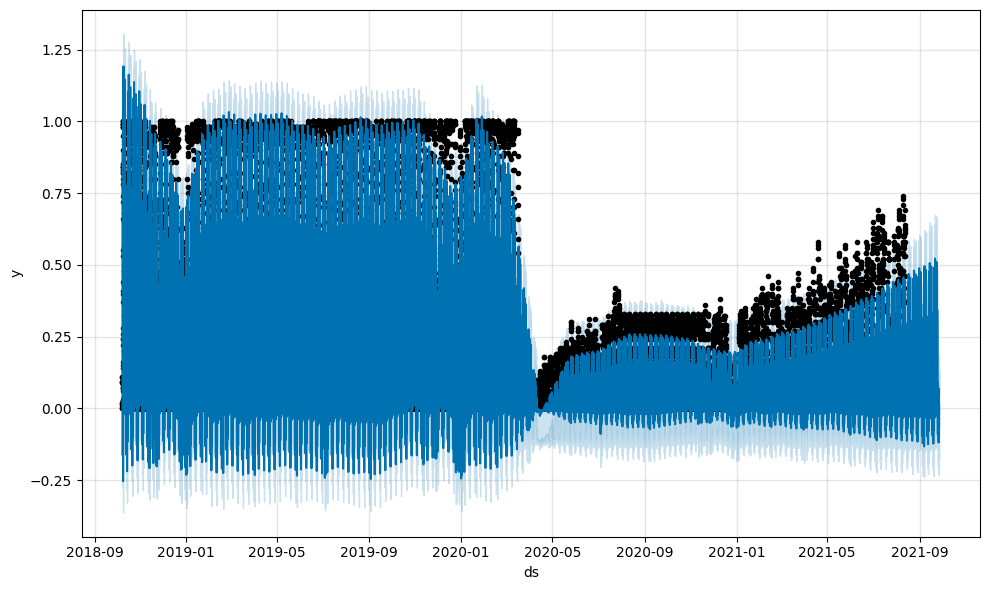

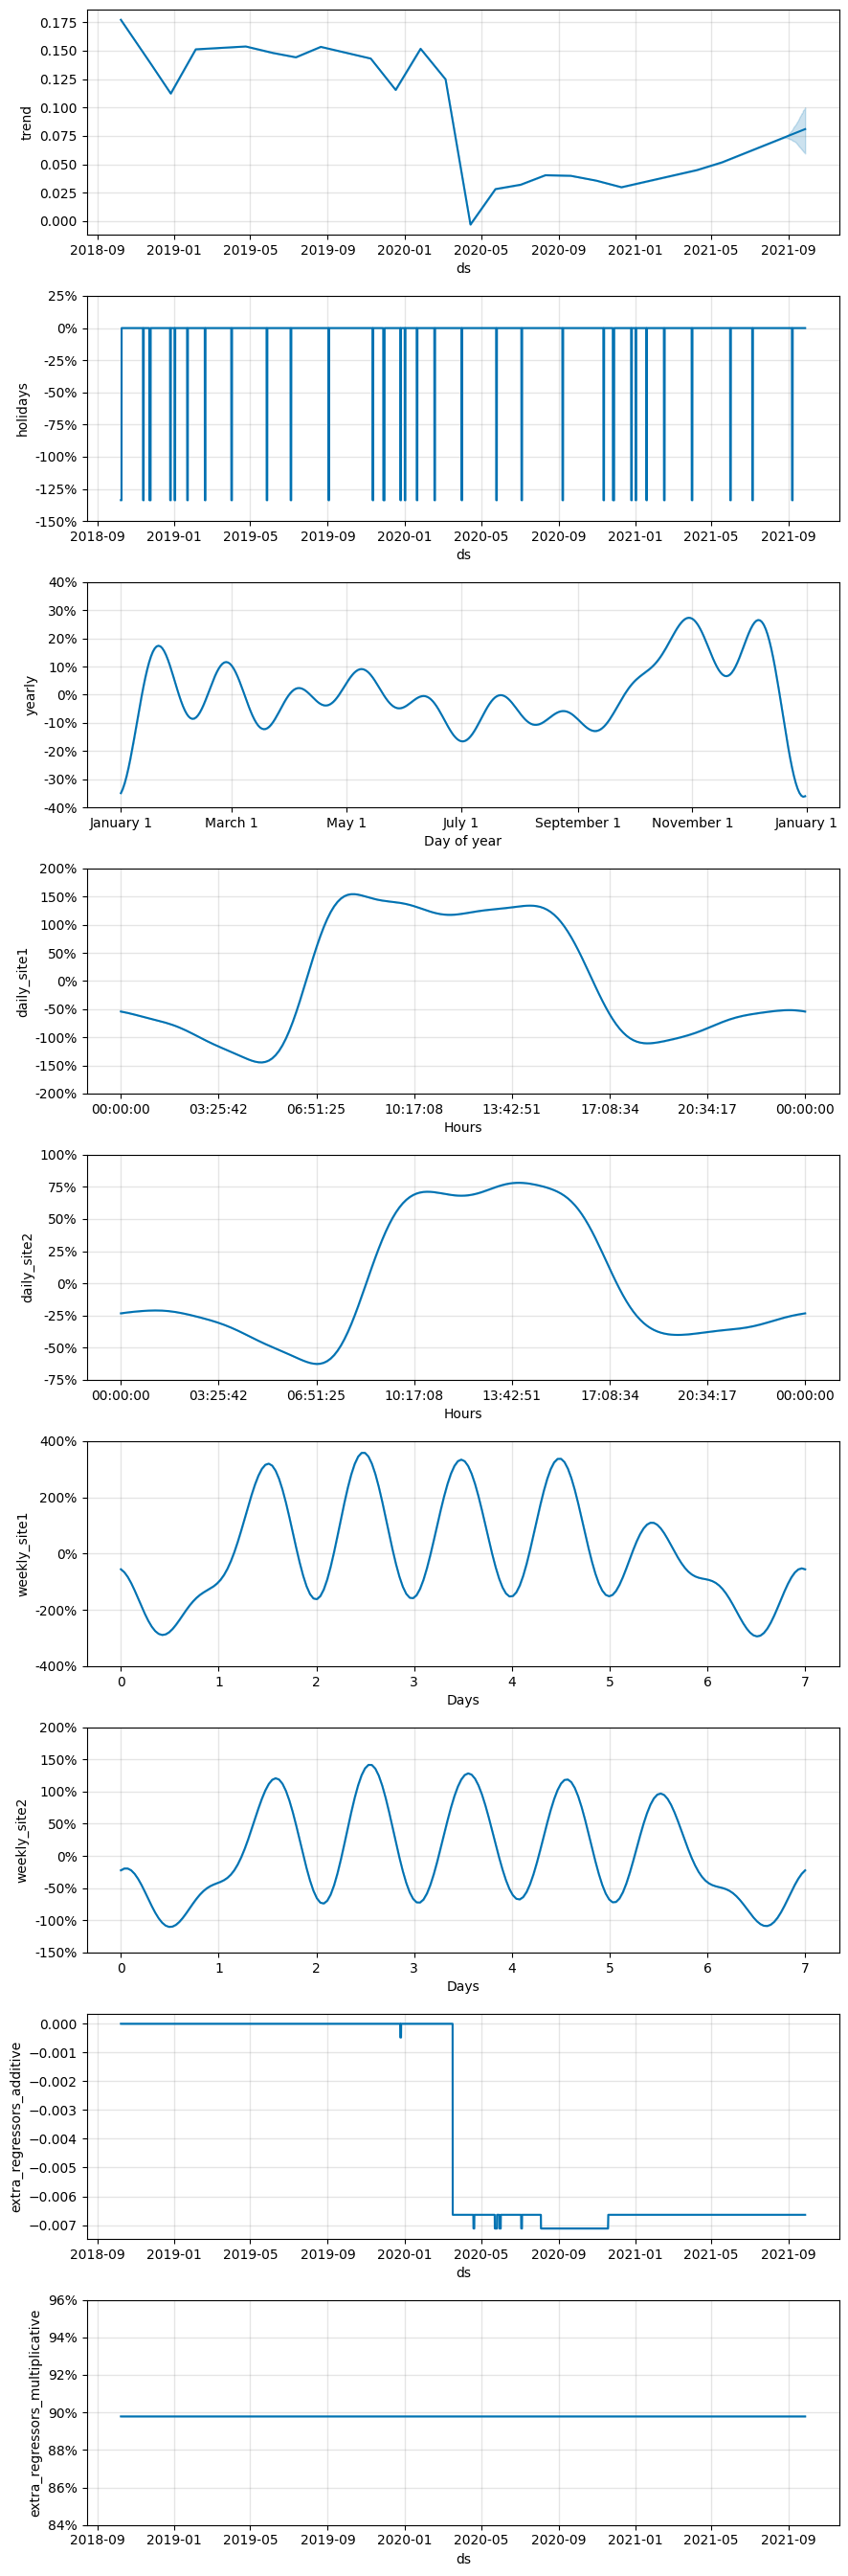

In [14]:
model.plot(forecast)
plt.show()

model.plot_components(forecast)
plt.show()

<span style ="font-size: 20px; font-weight: bold;color: #43556A;">
        9. Make a specific prediction
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

In [15]:
# Let us 
specific_forecast = forecast.loc[forecast['ds'] == '2021-09-22 12:00']
print("Forecasted utilisation for 22.09.2021 12 AM:", specific_forecast['yhat'].values[0])

Forecasted utilisation for 22.09.2021 12 AM: 0.5033943650602936


<span style ="font-size: 20px; font-weight: bold;color: #43556A;">
        10. Plot predicted utilzations for the test split
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

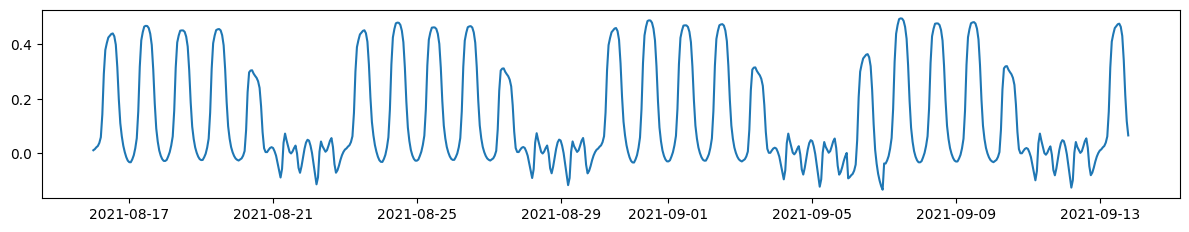

In [18]:
plot_forecast(forecast, '2021-08-16', '2021-09-13 19:00')

<span style ="font-size: 20px; font-weight: bold;color: #43556A;">
        11. Plot 1 entire week into 'the future'
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

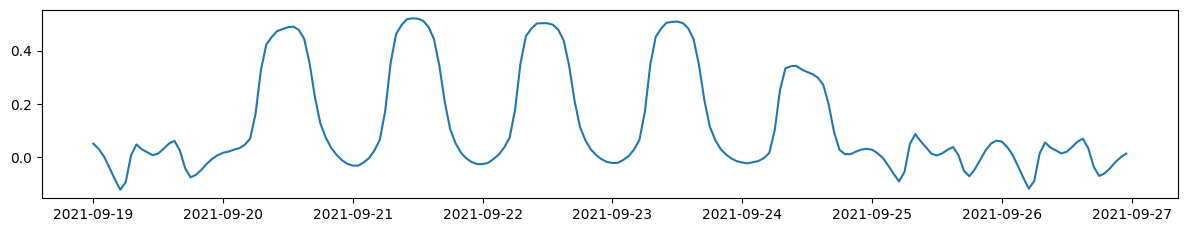

In [24]:
plot_forecast(forecast,  '2021-09-19 00:00', '2021-09-26 23:00')

We can observe the strong weekly and hourly cycles. Monday through fridays has the highest peak utilizations, friday has slightly lower ones and on the weekend there is a strong dropoff.

<span style ="font-size: 20px; font-weight: bold;color: #43556A;">
        12. Plot 1 weekday into 'the future'
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

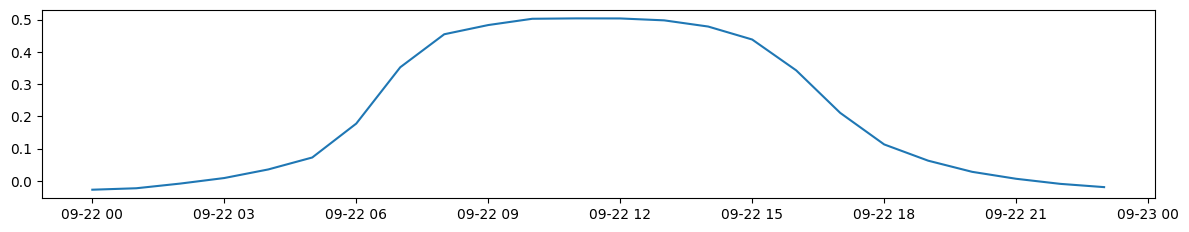

In [27]:
plot_forecast(forecast,  '2021-09-22 00:00', '2021-09-22 23:00')

We can observe the strong hourly cycles, as well. During the hours 5 and 12 there is a sharp incline followed by stagnation and a steep dropoff after 15:00. 

<span style ="font-size: 20px; font-weight: bold;color: #43556A;">
        13. Plot 1 day on a weekend into 'the future'
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

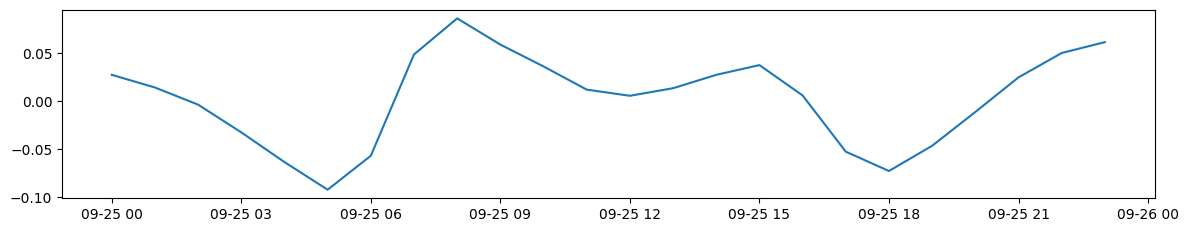

In [29]:
plot_forecast(forecast,  '2021-09-25 00:00', '2021-09-25 23:00')

We do not observe such an hourly cycle on the day on a weekend. Additionally, some predicted utilizations are below 0. This happens for several hours and days were the peak utilizations are close to 0.